<a href="https://colab.research.google.com/github/EmiiFernandez/actividades_data_sciente_ypf/blob/main/notebook/C24_Notebook-28.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

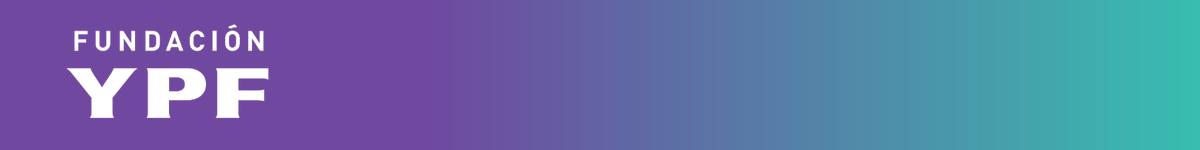

# Fundación YPF - Data Science

## Notebook 28: Clase práctica, clustering de punta a punta

### Índice de partes

* **Parte 0:** Preparación del entorno
* **Parte 1:** Repaso: lo que ya sabemos de clustering
* **Parte 2:** El caso: datos de cáncer de mama
* **Parte 3:** Análisis exploratorio
* **Parte 4:** Escalado y elección de k
* **Parte 5:** Clustering final e interpretación
* **Parte 6:** Mejora: validamos con el diagnóstico real y comparamos con DBSCAN
* **Parte 7:** Ejercicio para las salas de Zoom

## Parte 0: Preparación del entorno

Esta es una clase práctica: repasamos todo lo visto sobre clustering (Notebooks 23, 24, 25 y 26) y lo aplicamos de punta a punta, desde el análisis exploratorio hasta la mejora del modelo, sobre un dataset nuevo.

**Datasets:**

* `cancer_mamario.csv`: datos clínicos de 286 pacientes con cáncer de mama. Lo usamos en la parte guiada.
* `venta_autos.csv`: anuncios de autos usados (el mismo de la Notebook 24). Lo usamos en el ejercicio de las salas.

Antes de ejecutar, subí los archivos `cancer_mamario.csv` y `venta_autos.csv` al panel de archivos de Colab (ícono de carpeta a la izquierda).

In [2]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Parte 1: Repaso: lo que ya sabemos de clustering

Antes de meternos con el caso nuevo, repasamos las piezas que ya vimos y que hoy combinamos:

* **K-Means** (Notebook 23 y Notebook 24): agrupa alrededor de k centroides, minimizando la distancia de cada punto al centroide de su cluster. Necesitamos indicarle k de antemano y siempre hay que escalar las variables antes de usarlo.
* **DBSCAN** (Notebook 25): agrupa por densidad de puntos. No necesita que le indiquemos el número de clusters, encuentra formas no esféricas y marca como ruido los puntos que no pertenecen a ningún grupo.
* **Método del codo** (Notebook 26): grafica la inercia de K-Means para distintos valores de k y busca el punto donde la mejora se empieza a achicar.
* **Coeficiente de Silhouette** (Notebook 26): mide, para cada punto, qué tan bien encaja en su cluster frente a los demás clusters. Un promedio más alto indica clusters más compactos y separados.

Hoy el objetivo es recorrer todo el proceso en un caso nuevo: desde que llega el dataset crudo hasta que decidimos si el modelo final es bueno.

## Parte 2: El caso: datos de cáncer de mama

Trabajamos con un dataset clínico real de pacientes con cáncer de mama. Cada fila es una paciente, con características del tumor y si hubo recurrencia de la enfermedad (columna `class`). Vamos a ignorar esa columna para el clustering (es la que después usamos para validar), y a ver si la estructura de los datos agrupa a las pacientes en perfiles clínicos razonables.

In [3]:
# Carga del dataset
url = "https://raw.githubusercontent.com/EmiiFernandez/actividades_data_sciente_ypf/main/dataset/"

In [3]:
dataset_cancer = "cancer_mamario.csv"
df_cancer = pd.read_csv(url+dataset_cancer)

cancer = df_cancer.copy()
print("Forma del dataset:", cancer.shape)
cancer.head()

Forma del dataset: (286, 10)


,class,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
0,no-recurrence-events,30-39,premeno,30-34,0-2,no,3,left,left_low,no
1,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,right,right_up,no
2,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,left,left_low,no
3,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,right,left_up,no
4,no-recurrence-events,40-49,premeno,0-4,0-2,no,2,right,right_low,no


### 2.1 Limpieza y codificación de variables

Varias columnas son rangos de texto (`age`, `tumor-size`, `inv-nodes`) en lugar de números. Para poder calcular distancias necesitamos convertirlas a un valor numérico: usamos el punto medio de cada rango. También revisamos si hay valores faltantes, que en este dataset están marcados con el signo `?`.

In [ ]:
def punto_medio(rango):
    extremos = rango.split("-")
    return (int(extremos[0]) + int(extremos[1])) / 2

for col in ["age", "tumor-size", "inv-nodes"]:
    cancer[col + "_num"] = cancer[col].apply(punto_medio)

print("Valores '?' por columna:")
print((cancer == "?").sum()[lambda s: s > 0])

Valores '?' por columna:
node-caps      8
breast-quad    1
dtype: int64


`node-caps` tiene 8 valores faltantes y `breast-quad` tiene 1, sobre 286 pacientes: es poco, pero no vamos a usar esas dos columnas (ni `breast`, que solo indica el lado del cuerpo) para agrupar. Nos quedamos con las variables clínicas numéricas que describen la severidad del caso: edad, tamaño del tumor, cantidad de ganglios invadidos y grado de malignidad.

In [ ]:
variables = ["age_num", "tumor-size_num", "inv-nodes_num", "deg-malig"]
datos = cancer[variables].copy()
datos.describe().round(1)

,age_num,tumor-size_num,inv-nodes_num,deg-malig
count,286.0,286.0,286.0,286.0
mean,51.1,26.4,2.6,2.0
std,10.1,10.5,3.5,0.7
min,24.5,2.0,1.0,1.0
25%,44.5,22.0,1.0,2.0
50%,54.5,27.0,1.0,2.0
75%,54.5,32.0,4.0,3.0
max,74.5,52.0,25.0,3.0


## Parte 3: Análisis exploratorio

Miramos la distribución de cada variable clínica y cómo se relaciona con la recurrencia real (`class`), que todavía no usamos para agrupar pero nos sirve para entender el problema.

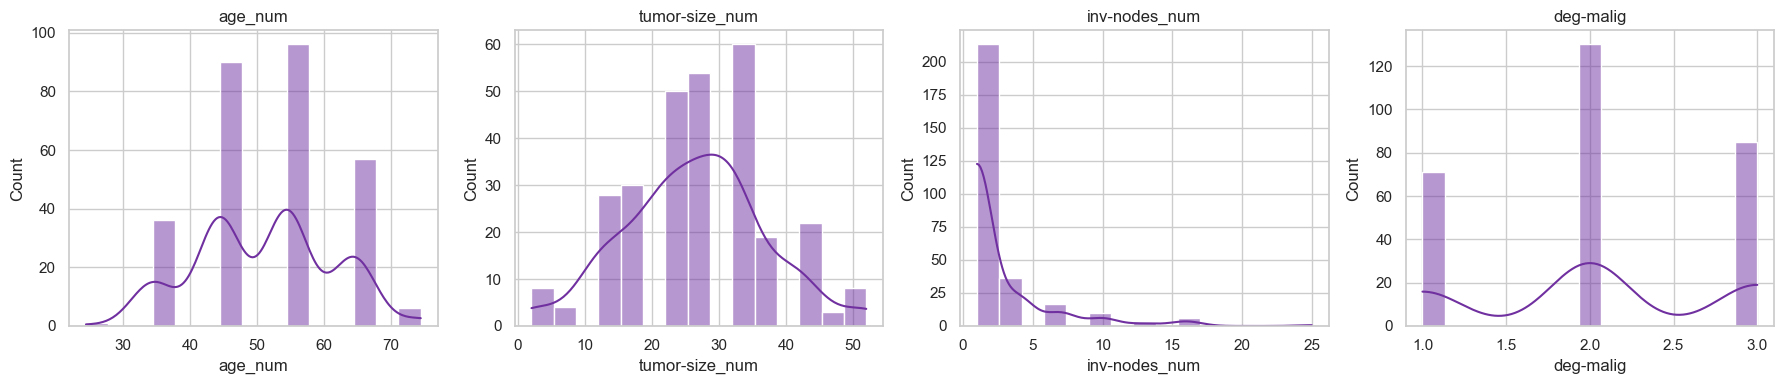

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, col in zip(ax, variables):
    sns.histplot(datos[col], bins=15, kde=True, ax=a, color="#7030A0")
    a.set_title(col)
plt.tight_layout()
plt.show()

In [ ]:
cancer.groupby("class")[variables].mean().round(2)

,age_num,tumor-size_num,inv-nodes_num,deg-malig
class,,,,
no-recurrence-events,51.61,25.21,1.96,1.91
recurrence-events,50.03,29.24,4.04,2.39


Las pacientes con recurrencia tienen, en promedio, tumores más grandes, más ganglios invadidos y mayor grado de malignidad. Son señales clínicas razonables: ahora vemos si el clustering, que no usa la etiqueta `class`, encuentra esta misma estructura por sí solo.

## Parte 4: Escalado y elección de k

Las cuatro variables están en escalas distintas (la edad va de 0 a 100, el grado de malignidad de 1 a 3), así que las escalamos antes de calcular distancias. Después usamos el método del codo y el coeficiente de Silhouette, igual que en la Notebook 26, para elegir cuántos clusters pedirle a K-Means.

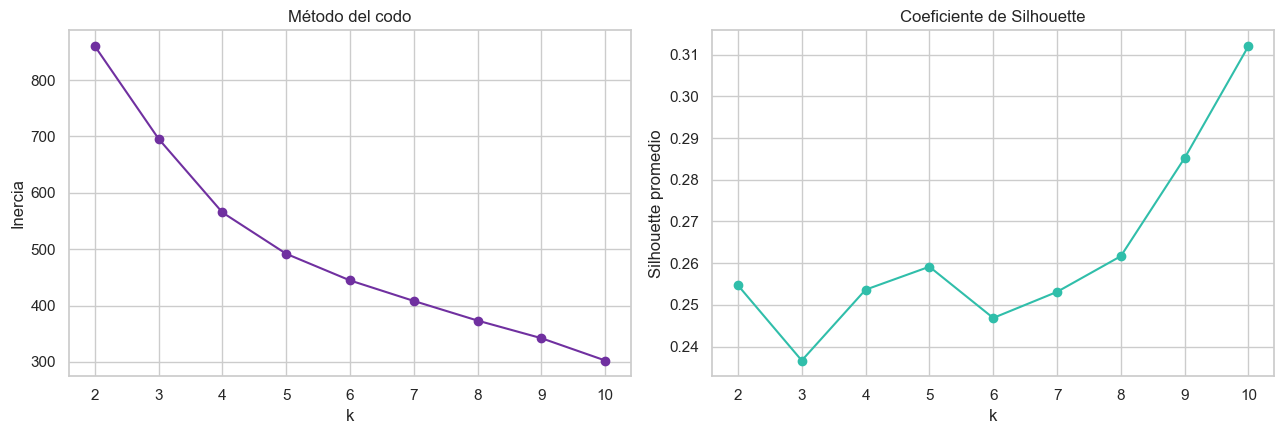

,k,inercia,silhouette
0,2,860.280,0.255
1,3,695.727,0.237
2,4,565.072,0.254
3,5,491.767,0.259
4,6,444.547,0.247
5,7,408.117,0.253
6,8,373.283,0.262
7,9,342.027,0.285
8,10,302.472,0.312


In [ ]:
X = StandardScaler().fit_transform(datos)

valores_k = range(2, 11)
inercias = []
siluetas = []
for k in valores_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(list(valores_k), inercias, "o-", color="#7030A0")
ax[0].set_title("Método del codo")
ax[0].set_xlabel("k")
ax[0].set_ylabel("Inercia")

ax[1].plot(list(valores_k), siluetas, "o-", color="#30BEAA")
ax[1].set_title("Coeficiente de Silhouette")
ax[1].set_xlabel("k")
ax[1].set_ylabel("Silhouette promedio")
plt.tight_layout()
plt.show()

pd.DataFrame({"k": list(valores_k), "inercia": inercias, "silhouette": siluetas}).round(3)

Igual que nos pasó con los compradores de Black Friday en la Notebook 24: acá tampoco hay un codo marcado ni un pico claro de Silhouette. La inercia baja de forma gradual y el Silhouette sube despacio a medida que agregamos clusters, porque con más grupos siempre es un poco más fácil separar puntos. Cuando el gráfico no decide, priorizamos la interpretabilidad: elegimos **k = 2**, que además nos deja comparar directamente contra las dos categorías reales de la columna `class` (con recurrencia y sin recurrencia) en la Parte 6.

In [ ]:
mejor_k = 2

## Parte 5: Clustering final e interpretación

Entrenamos K-Means con el k elegido y describimos el perfil clínico de cada cluster, en las unidades originales (no escaladas) para que sea más fácil de leer.

In [ ]:
kmeans = KMeans(n_clusters=mejor_k, n_init=10, random_state=RANDOM_STATE).fit(X)
cancer["cluster"] = kmeans.labels_

perfil = cancer.groupby("cluster").agg(
    pacientes=("deg-malig", "size"),
    edad=("age_num", "mean"),
    tumor=("tumor-size_num", "mean"),
    ganglios=("inv-nodes_num", "mean"),
    malignidad=("deg-malig", "mean"),
).round(2)
perfil

,pacientes,edad,tumor,ganglios,malignidad
cluster,,,,,
0,167,51.69,21.91,1.34,1.59
1,119,50.38,32.71,4.30,2.70


Cada cluster describe un perfil clínico distinto en términos de tamaño del tumor, ganglios invadidos y grado de malignidad. El siguiente paso, como en cualquier modelo de clustering, es preguntarnos si esta separación es útil: en la parte final la comparamos contra la recurrencia real.

## Parte 6: Mejora: validamos con el diagnóstico real y comparamos con DBSCAN

Esta columna (`class`) no se usó para entrenar el modelo, así que nos sirve como una validación externa: si el clustering encontró algo clínicamente real, los clusters deberían relacionarse con la recurrencia observada. Además, probamos DBSCAN sobre los mismos datos escalados para ver si conviene como alternativa, igual que comparamos K-Means y DBSCAN en la Notebook 26.

In [ ]:
tabla = pd.crosstab(cancer["cluster"], cancer["class"])
tabla

class,no-recurrence-events,recurrence-events
cluster,,
0,136,31
1,65,54


In [ ]:
ari_kmeans = adjusted_rand_score(cancer["class"], cancer["cluster"])

dbscan = DBSCAN(eps=1.2, min_samples=10).fit(X)
cancer["cluster_dbscan"] = dbscan.labels_
n_ruido = (cancer["cluster_dbscan"] == -1).sum()
ari_dbscan = adjusted_rand_score(cancer["class"], cancer["cluster_dbscan"])

print("Adjusted Rand Index K-Means vs diagnóstico real:", round(ari_kmeans, 3))
print("Adjusted Rand Index DBSCAN vs diagnóstico real:", round(ari_dbscan, 3))
print("Pacientes marcadas como ruido por DBSCAN:", n_ruido, "de", len(cancer))

Adjusted Rand Index K-Means vs diagnóstico real: 0.101
Adjusted Rand Index DBSCAN vs diagnóstico real: 0.079
Pacientes marcadas como ruido por DBSCAN: 25 de 286


El Adjusted Rand Index compara dos particiones y vale 0 cuando el parecido es el esperado al azar y 1 cuando son iguales. Ningún valor cercano a 1 acá es lo esperado: la recurrencia depende de más factores que los cuatro que usamos (y de factores que ningún dataset captura del todo), así que el clustering no tiene por qué reconstruir la etiqueta clínica. Lo que importa es que los perfiles de la Parte 5 son clínicamente razonables y que pudimos comparar dos algoritmos con el mismo criterio, de punta a punta: carga de datos, limpieza, exploración, escalado, elección de k, entrenamiento, interpretación y validación.

## Parte 7: Ejercicio para las salas de Zoom

**Dataset:** `venta_autos.csv` (el mismo de la Notebook 24). Son anuncios de autos usados. En la Notebook 24 este dataset quedó como ejercicio abierto porque el método del codo no marcaba un corte claro. Ahora que ya conocemos el coeficiente de Silhouette (Notebook 26), lo retomamos con esa herramienta adicional.

**Columnas que vas a usar:** `price`, `powerPS`, `kilometer` y `yearOfRegistration`. El dataset tiene valores extremos (autos con precio 0 o millonario, años mal cargados): ya los filtramos en la celda siguiente para que puedas ir directo a la parte de clustering.

**Tiempo:** 50 minutos. Al final, cada sala comparte sus conclusiones.

**Consigna:**

1. **Escalado.** Escalá las cuatro variables (`price`, `powerPS`, `kilometer`, `antiguedad`, ya calculada en la celda de carga) con `StandardScaler`.
2. **Método del codo.** Probá k de 2 a 10 sobre los datos escalados y graficá la inercia.
3. **Coeficiente de Silhouette.** Calculá el Silhouette promedio para los mismos valores de k y graficalo. ¿Coincide el k sugerido con el del codo?
4. **K-Means final.** Entrená K-Means con el k que elegiste.
5. **Perfil de los clusters.** Calculá el perfil (medias de `price`, `powerPS`, `kilometer`, `antiguedad`) para cada cluster y ponele un nombre a cada grupo (por ejemplo, autos nuevos de alta gama, autos usados económicos, etc.).

In [4]:
# Cargamos el dataset del ejercicio y filtramos valores extremos
dataset_autos = "venta_autos.csv"
df_autos = pd.read_csv(url+dataset_autos)
autos = df_autos.copy()

autos = autos[
    (autos["price"].between(100, 100000))
    & (autos["powerPS"].between(1, 500))
    & (autos["yearOfRegistration"].between(1960, 2016))
]
autos["antiguedad"] = 2016 - autos["yearOfRegistration"]

print("Autos despues del filtro:", len(autos))
autos[["price", "powerPS", "kilometer", "antiguedad"]].describe().round(1)

Autos despues del filtro: 41774


,price,powerPS,kilometer,antiguedad
count,41774.0,41774.0,41774.0,41774.0
mean,6160.1,126.5,125547.4,12.8
std,7637.5,60.6,39229.1,6.6
min,100.0,1.0,5000.0,0.0
25%,1450.0,80.0,100000.0,8.0
50%,3500.0,116.0,150000.0,13.0
75%,7990.0,150.0,150000.0,17.0
max,98500.0,500.0,150000.0,56.0


In [6]:
# 1. Escalado
X = StandardScaler().fit_transform(autos[["price", "powerPS", "kilometer", "antiguedad"]])

# Silhouette compara cada punto contra todos los demas (costo n^2): con ~42.000 autos
# tarda muchisimo. Lo calculamos sobre una muestra de 5.000 puntos, que da un valor muy parecido.
valores_k = range(2, 11)
inercias = []
siluetas = []
for k in valores_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X, km.labels_, sample_size=5000, random_state=RANDOM_STATE))

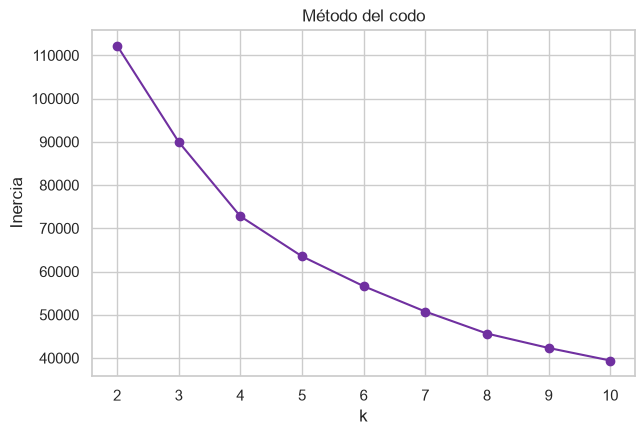

In [8]:
# 2. Metodo del codo
plt.figure(figsize=(7, 4.5))
plt.plot(list(valores_k), inercias, "o-", color="#7030A0")
plt.title("Método del codo")
plt.xlabel("k")
plt.ylabel("Inercia")
plt.show()

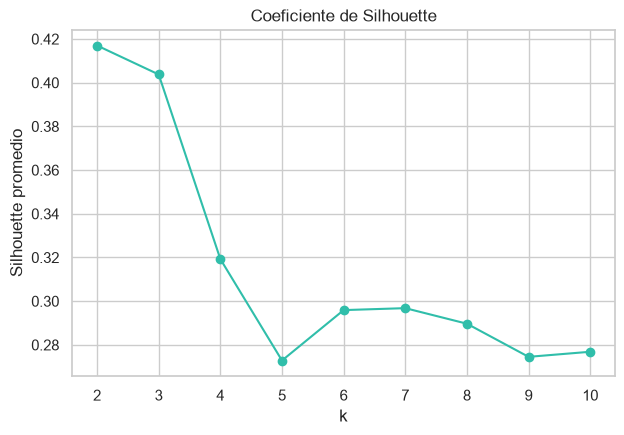

In [10]:
# 3. Coeficiente de Silhouette
plt.figure(figsize=(7, 4.5))
plt.plot(list(valores_k), siluetas, "o-", color="#30BEAA")
plt.title("Coeficiente de Silhouette")
plt.xlabel("k")
plt.ylabel("Silhouette promedio")
plt.show()


In [11]:
pd.DataFrame({"k": list(valores_k), "inercia": inercias, "silhouette": siluetas}).round(3)

,k,inercia,silhouette
0,2,112263.092,0.417
1,3,89966.870,0.404
2,4,72776.237,0.319
3,5,63512.635,0.273
4,6,56616.441,0.296
5,7,50747.498,0.297
6,8,45659.987,0.290
7,9,42329.472,0.275
8,10,39422.717,0.277


In [13]:
# 4. K-Means final
kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X)
autos["cluster"] = kmeans.labels_

perfil = autos.groupby("cluster").agg(
    precio = ("price", "mean"),
    powerPS = ("powerPS", "mean"),
    kilometer = ("kilometer", "mean"),
    antiguedad = ("antiguedad", "mean"),
).round(2)
perfil

,precio,powerPS,kilometer,antiguedad
cluster,,,,
0,8902.27,107.18,61838.11,7.51
1,3077.29,111.87,144298.71,14.97
2,19019.89,234.29,115309.31,8.46


In [14]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X)
autos["cluster"] = kmeans.labels_

perfil = autos.groupby("cluster").agg(
    precio = ("price", "mean"),
    powerPS = ("powerPS", "mean"),
    kilometer = ("kilometer", "mean"),
    antiguedad = ("antiguedad", "mean"),
).round(2)
perfil

,precio,powerPS,kilometer,antiguedad
cluster,,,,
0,27322.70,245.08,80328.75,6.60
1,8451.43,105.75,61522.28,7.52
2,1927.18,94.01,142679.69,17.51
3,6687.63,159.77,144937.07,10.23


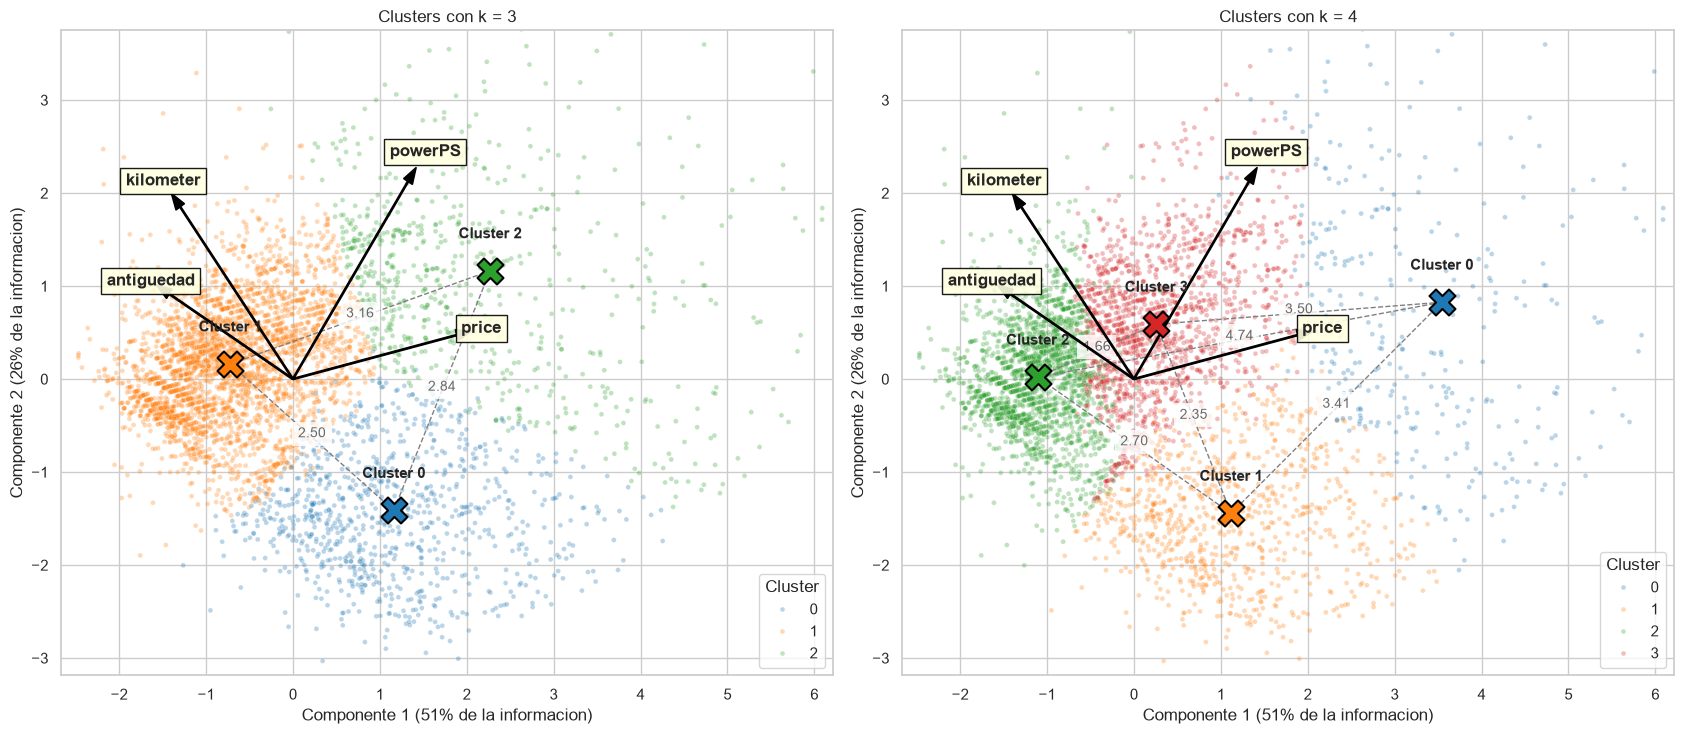

,Componente 1,Componente 2
price,0.63,0.16
powerPS,0.44,0.71
kilometer,-0.43,0.62
antiguedad,-0.47,0.31


In [ ]:
# 5. Perfil de los clusters
# Mapa de los clusters: k = 3 contra k = 4
from sklearn.decomposition import PCA
from itertools import combinations

columnas = ["price", "powerPS", "kilometer", "antiguedad"]
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
X2 = pca.transform(X)
varianza = pca.explained_variance_ratio_ * 100
muestra = np.random.RandomState(RANDOM_STATE).choice(len(X2), 5000, replace=False)
colores = sns.color_palette("tab10")

fig, ax = plt.subplots(1, 2, figsize=(17, 7.5))
for a, k in zip(ax, [3, 4]):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    centros_2d = pca.transform(km.cluster_centers_)

    # Autos
    sns.scatterplot(x=X2[muestra, 0], y=X2[muestra, 1], hue=km.labels_[muestra],
                    palette=colores[:k], alpha=0.3, s=12, ax=a)

    # Distancia entre centroides (calculada en las 4 variables escaladas, no en el plano)
    for i, j in combinations(range(k), 2):
        (x1, y1), (x2, y2) = centros_2d[i], centros_2d[j]
        dist = np.linalg.norm(km.cluster_centers_[i] - km.cluster_centers_[j])
        a.plot([x1, x2], [y1, y2], "--", color="gray", lw=1)
        a.text((x1 + x2) / 2, (y1 + y2) / 2, f"{dist:.2f}", fontsize=10, color="dimgray",
               ha="center", bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))

    # Centroides
    for c, (cx, cy) in enumerate(centros_2d):
        a.scatter(cx, cy, marker="X", s=350, color=colores[c], edgecolor="black", linewidth=1.5, zorder=5)
        a.text(cx, cy + 0.35, f"Cluster {c}", fontsize=11, weight="bold", ha="center", zorder=6)

    # Flechas de las variables
    for v, col in enumerate(columnas):
        fx, fy = pca.components_[0, v] * 3, pca.components_[1, v] * 3
        a.arrow(0, 0, fx, fy, color="black", width=0.015, head_width=0.12, zorder=4)
        a.text(fx * 1.15, fy * 1.15, col, fontsize=12, weight="bold", ha="center", va="center",
               bbox=dict(facecolor="lightyellow", edgecolor="black", alpha=0.9), zorder=6)

    # Recortamos los extremos para que no achiquen el grafico
    a.set_xlim(np.percentile(X2[:, 0], [0.5, 99.5]) + [-0.5, 0.5])
    a.set_ylim(np.percentile(X2[:, 1], [0.5, 99.5]) + [-0.5, 0.5])
    a.set_xlabel(f"Componente 1 ({varianza[0]:.0f}% de la informacion)")
    a.set_ylabel(f"Componente 2 ({varianza[1]:.0f}% de la informacion)")
    a.set_title(f"Clusters con k = {k}")
    a.legend(title="Cluster", loc="lower right")

plt.tight_layout()
plt.show()

# Peso de cada variable en los 2 ejes del grafico
pd.DataFrame(pca.components_.T, index=columnas, columns=["Componente 1", "Componente 2"]).round(2)
